# FDTD devices: photonic-crystal waveguides and cavities, a grating coupler and a metalens

Notebook [62](62_fdtd_periodic_structures.ipynb) computed what periodic
structures do on their own: diffraction orders, band structures, a band
gap. This one builds devices from them:

1. a **photonic-crystal waveguide**: a missing row of rods guides light
   inside the band gap; its band from a supercell, its transmission
   around a sharp 90° bend,
2. a **photonic-crystal cavity**: a missing rod traps light; its Q grows
   exponentially with the crystal around it,
3. a **grating coupler** from a single-mode fibre into a silicon
   waveguide: efficiency against wavelength and fibre angle, and the
   phase-matching condition that sets the peak,
4. a **metalens**: a phase library of TiO₂ pillars from periodic unit
   cells, a lens assembled from it, and a full FDTD run of the lens
   against the local-periodic model that designed it.

Everything is 2D: rods and pillars are infinitely long along z, and the
grating coupler is a cross section. Lengths in µm or in units of the
lattice constant $a$, frequencies $a/\lambda$.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from pyoptics import fdtd
from pyoptics.fdtd import plot as fplot

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
print("numba kernels available:", fdtd.numba_available)
ROD = fdtd.Medium(8.9)
DISC = fdtd.Circle((0, 0), 0.2)
GAP = (0.323, 0.442)          # Ez band gap of this lattice (notebook 62)
t_start = time.perf_counter()

numba kernels available: True


## 1. A photonic-crystal waveguide

The square lattice of rods (ε = 8.9, r = 0.2a) of notebook 62 has a band
gap for the Ez polarization between $a/\lambda$ = 0.323 and 0.442: light
at these frequencies cannot enter it. Remove a row of rods and the light
in that row is trapped on both sides by the gap: a **line-defect
waveguide**. `fdtd.Lattice` places a shape on every lattice site except
the removed ones.

Its modes come from a **supercell**: one period along the waveguide,
several rows across it, Bloch boundaries in both directions. The
supercell repeats the waveguide every N rows, but with 3 rows of rods on
each side the copies are decoupled inside the gap. `bloch_modes(...,
region=...)` places the dipoles and probes in the defect row, which picks
out the guided mode.

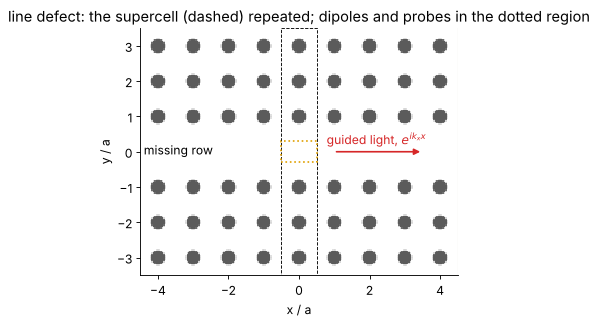

In [2]:
N_SC = 7
grid_sc = fdtd.Grid((1.0, float(N_SC)), 1/24)
supercell = [(fdtd.Lattice(DISC, (1, 0), (0, 1), (1, N_SC), remove=[(0, 0)]), ROD)]
sk = fdtd.Simulation(grid_sc, supercell, [], [], boundaries=(fdtd.Bloch(1.0), "periodic"))
fig, ax = plt.subplots(figsize=(11, 4.2))
fplot.plot_structure(sk, ax=ax, periods=9)
ax.add_patch(plt.Rectangle((-0.5, -0.3), 1.0, 0.6, fill=False, ec=fplot.SOURCE_COLOR, lw=1.5, ls=":"))
ax.annotate("", (3.5, 0), (1.0, 0), arrowprops=dict(arrowstyle="-|>", color="C3", lw=1.5))
ax.text(2.2, 0.12, r"guided light, $e^{ik_x x}$", color="C3", ha="center", va="bottom")
ax.text(-4.4, 0.05, "missing row", va="center")
ax.set(xlim=(-4.5, 4.5), ylim=(-3.5, 3.5), xlabel="x / a", ylabel="y / a",
       title="line defect: the supercell (dashed) repeated; dipoles and probes in the dotted region")
plt.tight_layout()

guided band inside the bulk gap: 0.319 to 0.454


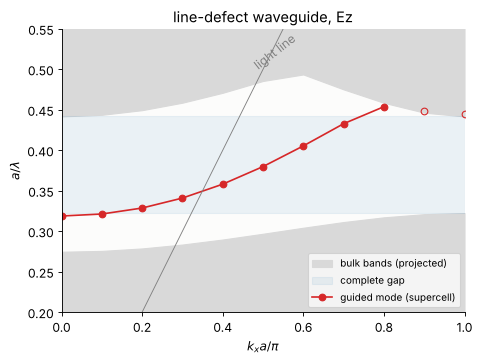

In [3]:
kxs = np.linspace(0, 1, 11)*np.pi
# bulk bands projected on kx: the extremes of bands 1 and 2 over ky
cell = fdtd.Grid((1.0, 1.0), 1/24)
lower, upper = [], []
for kx in kxs:
    f_lo, f_hi = [], []
    for ky in np.linspace(0, 1, 6)*np.pi:
        f = fdtd.bloch_modes(cell, [(DISC, ROD)], (kx, ky), band=(1/0.7, 1/0.05)).frequency
        f_lo += list(f[f < 0.38])
        f_hi += list(f[f > 0.38])
    lower.append(max(f_lo))
    upper.append(min(f_hi))
guided = []
for kx in kxs:
    r = fdtd.bloch_modes(grid_sc, supercell, (kx, 0.0), band=(1/0.46, 1/0.30),
                         region=((-0.5, 0.5), (-0.3, 0.3)))
    guided.append(r.frequency[np.argmax(r.amplitude)])
guided = np.array(guided)

fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.fill_between(kxs/np.pi, 0, lower, color="0.85", label="bulk bands (projected)")
ax.fill_between(kxs/np.pi, upper, 0.6, color="0.85")
ax.axhspan(*GAP, color="C0", alpha=0.08, label="complete gap")
inside = (guided > np.array(lower)) & (guided < np.array(upper))
ax.plot(kxs[inside]/np.pi, guided[inside], "o-", color="C3", label="guided mode (supercell)")
ax.plot(kxs[~inside]/np.pi, guided[~inside], "o", color="C3", mfc="none")
ax.plot([0, 0.6], [0, 0.6], color="0.5", lw=0.8)
ax.text(0.47, 0.5, "light line", color="0.5", rotation=38)
ax.set(xlim=(0, 1), ylim=(0.2, 0.55), xlabel=r"$k_x a/\pi$", ylabel=r"$a/\lambda$",
       title="line-defect waveguide, Ez")
ax.legend(loc="lower right", fontsize=9)
print("guided band inside the bulk gap: %.3f to %.3f" % (guided[inside].min(), guided[inside].max()))

The guided band runs from the bottom of the gap at $k_x = 0$ upwards,
crosses the complete gap and continues a little above it (at a given
$k_x$ only the projected bulk bands matter, and there the gap is wider),
until it meets them near $k_x = 0.85\pi/a$ (open circles: no longer
confined). Most of the band lies above the light line: an empty row of
air guides nothing by total internal reflection, only the band gap
confines this light.

### Transmission around a sharp bend

A conventional waveguide radiates at a bend whose radius is comparable
to the wavelength (notebook 60). In a photonic crystal there is nowhere
to radiate to. The bent waveguide below turns by 90° within a single
lattice site; a line source in the waveguide launches a pulse covering
the gap, and two `Flux` lines measure what goes in and what comes out.
A straight waveguide of the same length is the reference.

The crystal runs into the absorbing layer; a PML on a periodic medium
reflects more than on a homogeneous one, and slow guided light needs a
long, gentle one (here 10 lattice constants with a quadratic grading).

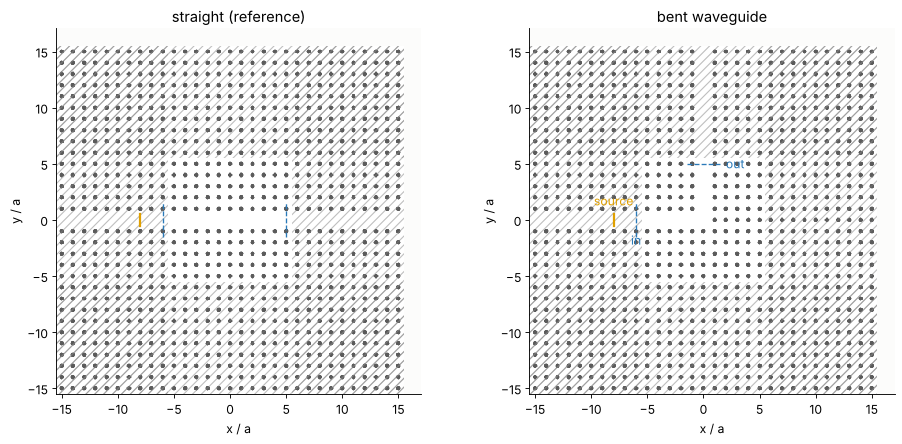

In [4]:
N_X = 31
H_PC = 1/20
fs = np.linspace(0.30, 0.45, 151)
pulse_pc = fdtd.GaussianPulse(1/0.38, bandwidth=0.2)


def pc_guide(bend, dft=None):
    half = N_X//2
    rem = [(i, 0) for i in range(-half, 1 if bend else half + 1)]
    if bend:
        rem += [(0, j) for j in range(1, half + 1)]
    st = [(fdtd.Lattice(DISC, (1, 0), (0, 1), (N_X, N_X), remove=rem), ROD)]
    inc = fdtd.Flux(-6.0, 1/fs, axis=0, extent=(-1.5, 1.5))
    out = fdtd.Flux(5.0, 1/fs, axis=1 if bend else 0, extent=(-1.5, 1.5))
    src = fdtd.LineSource(-8.0, pulse_pc, axis=0, extent=(-0.5, 0.5))
    sim = fdtd.Simulation(fdtd.Grid((float(N_X), float(N_X)), H_PC), st, [src],
                          [inc, out] + ([dft] if dft else []), mode="Ez",
                          boundaries=fdtd.PML(200, order=2, reflection=1e-4))
    return sim, inc, out


fig, axs = plt.subplots(1, 2, figsize=(12, 5.6))
for ax, bend in zip(axs, (False, True)):
    fplot.plot_structure(pc_guide(bend)[0], ax=ax)
    ax.set(xlabel="x / a", ylabel="y / a", title="bent waveguide" if bend else "straight (reference)")
axs[1].text(-8.0, 1.3, "source", color=fplot.SOURCE_COLOR, ha="center")
axs[1].text(-6.0, -2.2, "in", color=fplot.MONITOR_COLOR, ha="center")
axs[1].text(2.0, 5.0, "out", color=fplot.MONITOR_COLOR, va="center")
plt.tight_layout()

two runs of 620 x 620 cells: 153 s


bend: T = 0.900 to 1.012 between a/lambda = 0.33 and 0.44, mean 0.971


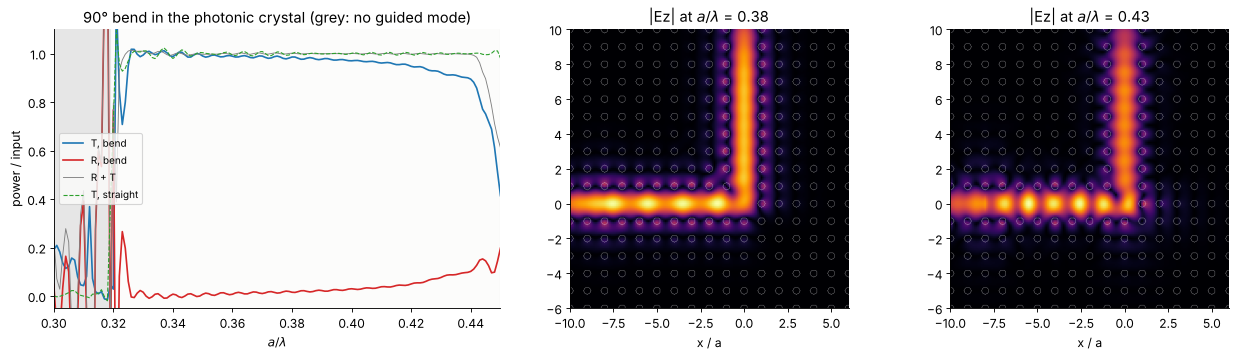

In [5]:
t0 = time.perf_counter()
sim_s, inc_s, out_s = pc_guide(False)
sim_s.run(time=1200)
dft_b = fdtd.DFTField([1/0.38, 1/0.43], components=["Ez"], stride=2)
sim_b, inc_b, out_b = pc_guide(True, dft_b)
sim_b.run(time=1200)
print("two runs of %d x %d cells: %.0f s" % (*sim_b.grid.shape, time.perf_counter() - t0))
P_in = inc_s.flux()
T_bend = out_b.flux()/P_in
R_bend = 1 - inc_b.flux()/P_in
band = (fs > 0.33) & (fs < 0.44)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.3, 1, 1]})
axs[0].plot(fs, T_bend, color="C0", label="T, bend")
axs[0].plot(fs, R_bend, color="C3", label="R, bend")
axs[0].plot(fs, T_bend + R_bend, color="0.5", lw=0.8, label="R + T")
axs[0].plot(fs, out_s.flux()/P_in, color="C2", lw=1, ls="--", label="T, straight")
axs[0].axvspan(fs[0], guided[inside].min(), color="0.9")
axs[0].axvspan(guided[inside].max(), fs[-1], color="0.9")
axs[0].set(xlim=(fs[0], fs[-1]), ylim=(-0.05, 1.1), xlabel=r"$a/\lambda$", ylabel="power / input",
           title="90° bend in the photonic crystal (grey: no guided mode)")
axs[0].legend(fontsize=9, loc="center left")
x, y = dft_b.coords("Ez")
for ax, k, f in zip(axs[1:], (0, 1), (0.38, 0.43)):
    F = dft_b.field("Ez")[k]
    ax.imshow(np.abs(F).T, origin="lower", extent=fplot._extent((x, y)), cmap="inferno")
    fplot._structure_outline(ax, sim_b, color="w", lw=0.4, alpha=0.5)
    ax.set(xlim=(-10, 6), ylim=(-6, 10), title=r"|Ez| at $a/\lambda$ = %.2f" % f, xlabel="x / a")
plt.tight_layout()
print("bend: T = %.3f to %.3f between a/lambda = 0.33 and 0.44, mean %.3f"
      % (T_bend[band].min(), T_bend[band].max(), T_bend[band].mean()))

Across the guided band the bend passes 90 to 100 % of the light (97 %
on average between $a/\lambda$ = 0.33 and 0.44), and what it does not
pass it reflects (R + T = 1: nothing is lost to
radiation). Towards the upper end of the band the guided mode slows down
and the bend reflects more. The light simply cannot go anywhere else:
this is the classic demonstration of Mekis et al. (Phys. Rev. Lett. 77,
3787, 1996), here for this lattice. Outside the guided band (grey) the
source excites bulk modes and nothing is guided.

## 2. A photonic-crystal cavity

Remove a single rod instead of a row: light at a frequency in the gap is
trapped on all sides. A finite crystal leaks through its edges, and with
every ring of rods around the defect the leakage drops by the same
factor, the attenuation of the evanescent field across one lattice
constant: the Q grows exponentially. The dipole sits next to the defect,
the probe a little apart; the ring-down at the probe gives frequency and
Q (matrix pencil method, `fdtd.resonances`, notebook 60).

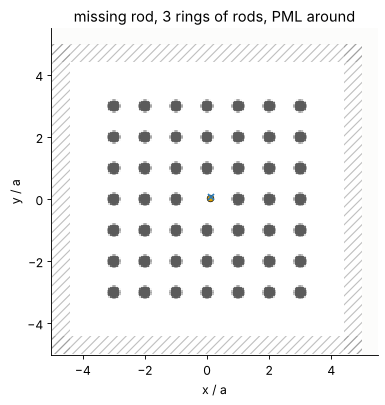

In [6]:
def cavity(rings, dft=None, h=1/20):
    n = 2*rings + 1
    st = [(fdtd.Lattice(DISC, (1, 0), (0, 1), (n, n), remove=[(0, 0)]), ROD)]
    pulse = fdtd.GaussianPulse(1/0.39, bandwidth=0.15)
    probe = fdtd.Probe((0.13, 0.07))
    sim = fdtd.Simulation(fdtd.Grid((n + 3.0, n + 3.0), h), st,
                          [fdtd.PointSource((0.1, 0.05), pulse)], [probe] + ([dft] if dft else []))
    return sim, probe, pulse


fig, ax = plt.subplots(figsize=(5.5, 5.2))
fplot.plot_structure(cavity(3)[0], ax=ax)
ax.set(xlabel="x / a", ylabel="y / a", title="missing rod, 3 rings of rods, PML around")
plt.tight_layout()

2 rings: a/lambda = 0.39489, Q = 116


3 rings: a/lambda = 0.39448, Q = 742


4 rings: a/lambda = 0.39440, Q = 4345


5 rings: a/lambda = 0.39438, Q = 24378


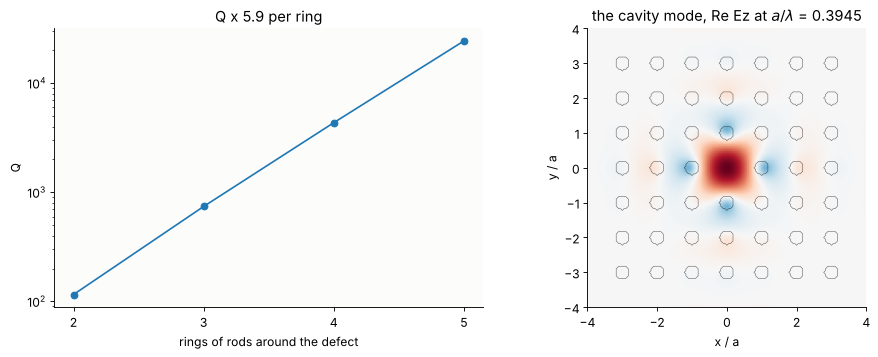

In [7]:
ring_list = [2, 3, 4, 5]
cav = []
for rings in ring_list:
    sim, probe, pulse = cavity(rings)
    sim.run(time=pulse.end + 200)
    sel = probe.times > pulse.end
    cav.append(fdtd.resonances(probe.values[sel], sim.dt, t0=probe.times[sel][0], band=(1/0.44, 1/0.32),
                               min_q=5))
    print("%d rings: a/lambda = %.5f, Q = %.0f" % (rings, cav[-1].frequency[0], cav[-1].Q[0]))
f_cav = cav[1].frequency[0]
dft_c = fdtd.DFTField([1/f_cav], components=["Ez"], start=120.0)
sim_c, _, _ = cavity(3, dft_c)
sim_c.run(time=200)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
Q = np.array([c.Q[0] for c in cav])
axs[0].semilogy(ring_list, Q, "o-")
axs[0].set(xlabel="rings of rods around the defect", ylabel="Q", xticks=ring_list,
           title="Q x %.1f per ring" % np.exp(np.polyfit(ring_list, np.log(Q), 1)[0]))
F = dft_c.field("Ez")[0]
x, y = dft_c.coords("Ez")
v = np.abs(F).max()
axs[1].imshow(np.real(F*np.exp(-1j*np.angle(F[np.argmin(abs(x)), np.argmin(abs(y))]))).T, origin="lower",
              extent=fplot._extent((x, y)), cmap="RdBu_r", vmin=-v, vmax=v)
fplot._structure_outline(axs[1], sim_c, lw=0.5)
axs[1].set(xlim=(-4, 4), ylim=(-4, 4), xlabel="x / a", ylabel="y / a",
           title=r"the cavity mode, Re Ez at $a/\lambda$ = %.4f" % f_cav)
plt.tight_layout()

The mode is a monopole: the field peaks in the empty site and changes
sign in the first ring of rods. Its frequency hardly depends on the
crystal around it; the Q grows by a constant factor per ring, from about
a hundred to tens of thousands. The run lengths stay short because the
matrix pencil method reads the decay off a few hundred periods, far
fewer than the decay time of the field (at Q = 24 000 the energy falls
by 1/e in about 10 000 periods). Convergence checks (not run here): the
frequency changes by 2e-4 from a/16 to a/48 cells, and Q by less than
1e-4 between runs of 200 and 2000 time units.

## 3. A grating coupler

Light from a single-mode fibre (mode field diameter about 10 µm) has to
get into a silicon waveguide 220 nm thick. A **grating coupler** etched
into the waveguide diffracts the light from the fibre into the
waveguide mode: the grating vector bridges the mismatch between the
in-plane wave number of the tilted beam and the propagation constant of
the waveguide,

$$\frac{2\pi}{\Lambda} = \beta - k_0\sin\theta \quad\Longleftrightarrow\quad
\lambda = \Lambda\,(\bar n_\mathrm{eff} - \sin\theta),$$

with $\bar n_\mathrm{eff}$ the average effective index of the etched and
unetched sections. The cross section below: silicon on 2 µm of oxide on
a silicon substrate, air above, 20 periods of 630 nm half etched 70 nm
deep; the beam (Gaussian, waist 5.2 µm) from a tilted line source; the
Ez polarization is the TE mode of the waveguide.

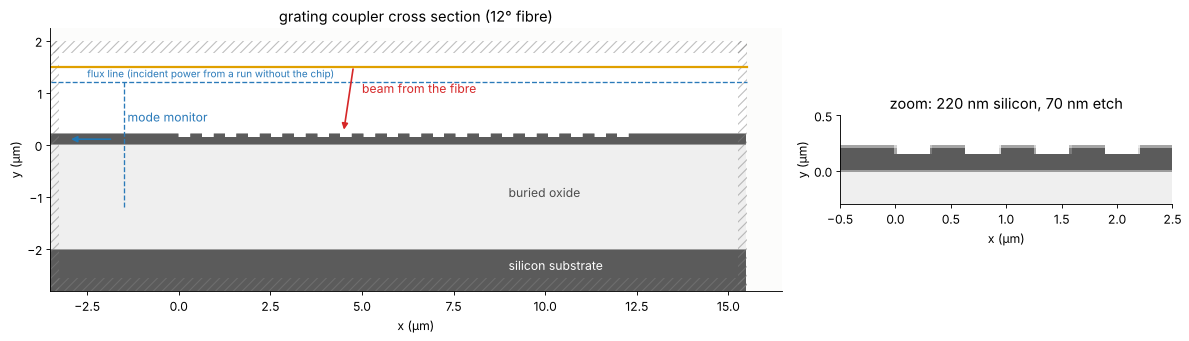

In [8]:
N_SI, N_OX = 3.48, 1.44
SI, OX = fdtd.Medium.from_index(N_SI), fdtd.Medium.from_index(N_OX)
LAM_G, N_PER, ETCH, W0 = 0.63, 20, 0.07, 5.2
wls_gc = np.linspace(1.45, 1.65, 41)
grid_gc = fdtd.Grid((19.0, 4.8), 0.02, center=(6.0, -0.4))
coupler = [(fdtd.Slab(-10, -2.0, axis=1), SI), (fdtd.Slab(-2.0, 0.0, axis=1), OX),
           (fdtd.Rect((0, 0.11), (60, 0.22)), SI),
           (fdtd.Lattice(fdtd.Rect((0, 0), (LAM_G/2, ETCH)), (LAM_G, 0), (0, 1), (N_PER, 1),
                         center=(LAM_G*(N_PER - 1)/2 + LAM_G/4, 0.22 - ETCH/2)), fdtd.VACUUM)]


def grating_coupler(theta_deg, structure=coupler, x_hit=4.5, dft=None):
    a = -np.radians(theta_deg)                 # tilted towards -x, the output side
    ys = 1.5
    xc = x_hit + ys*np.tan(np.radians(theta_deg))
    src = fdtd.LineSource(ys, fdtd.GaussianPulse(1.55, 0.1), axis=1, angle=a, n=1.0, center=xc,
                          transverse=lambda s: np.exp(-((s - xc)*np.cos(a)/W0)**2))
    down = fdtd.Flux(1.2, wls_gc, axis=1)
    wg = fdtd.ModeMonitor(-1.5, wls_gc, axis=0, extent=(-1.2, 1.2), every=4)
    sim = fdtd.Simulation(grid_gc, structure, [src], [down, wg] + ([dft] if dft else []), mode="Ez")
    return sim, down, wg


sim_g = grating_coupler(12.0)[0]
fig, axs = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [2.2, 1]})
for ax in axs:
    fplot.plot_structure(sim_g, ax=ax)
    ax.set(xlabel="x (µm)", ylabel="y (µm)")
axs[0].set(aspect="auto", title="grating coupler cross section (12° fibre)")
axs[0].annotate("", (4.5, 0.25), (4.5 + 1.25*np.tan(np.radians(12)), 1.5),
                arrowprops=dict(arrowstyle="-|>", color="C3", lw=1.5))
axs[0].text(5.0, 1.0, "beam from the fibre", color="C3")
axs[0].text(-1.4, 0.45, "mode monitor", color=fplot.MONITOR_COLOR)
axs[0].annotate("", (-3.0, 0.11), (-1.8, 0.11), arrowprops=dict(arrowstyle="-|>", color="C0", lw=1.5))
axs[0].text(9.0, -1.0, "buried oxide", color="0.3")
axs[0].text(9.0, -2.4, "silicon substrate", color="w")
axs[0].text(-2.5, 1.3, "flux line (incident power from a run without the chip)", fontsize=9,
            color=fplot.MONITOR_COLOR)
axs[1].set(xlim=(-0.5, 2.5), ylim=(-0.3, 0.5), title="zoom: 220 nm silicon, 70 nm etch")
plt.tight_layout()

104 s
peak efficiency 0.47; peak shift -8.0 nm per degree (prediction -8.1)


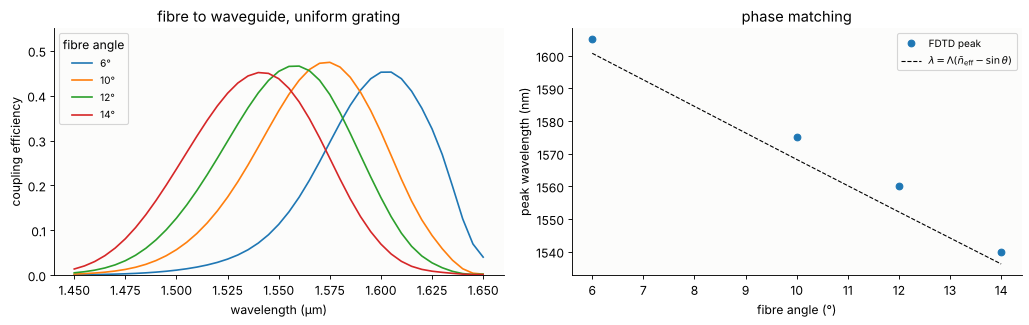

In [9]:
t0 = time.perf_counter()
eta = {}
dft_g = fdtd.DFTField([1.55], components=["Ez"], stride=2)
for th in (6.0, 10.0, 12.0, 14.0):
    sim0, down0, _ = grating_coupler(th, structure=[])
    sim0.run(time=60)
    sim, down, wg = grating_coupler(th, dft=dft_g if th == 12.0 else None)
    if th == 12.0:
        sim_g = sim
    sim.run(time=200)
    eta[th] = wg.power()[1]/(-down0.flux())      # backward (-x) mode power / incident power
print("%.0f s" % (time.perf_counter() - t0))


# phase matching with the dispersion of the average effective index
def n_avg(wl):
    def ne(t):
        h = 0.01
        y = (np.arange(-300, 300) + 0.5)*h
        eps = np.where((y > 0) & (y < t), N_SI**2, np.where(y < 0, N_OX**2, 1.0))
        return fdtd.waveguide_modes(eps, h, wl, "Ez")[0].n_eff
    return 0.5*(ne(0.22) + ne(0.22 - ETCH))


wl_n = np.array([1.45, 1.55, 1.65])
nn = np.array([n_avg(w) for w in wl_n])
n_of = lambda wl: np.polyval(np.polyfit(wl_n, nn, 2), wl)
pred = {th: brentq(lambda wl: wl - LAM_G*(n_of(wl) - np.sin(np.radians(th))), 1.2, 2.0) for th in eta}

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for th, c in zip(eta, ("C0", "C1", "C2", "C3")):
    axs[0].plot(wls_gc, eta[th], color=c, label="%.0f°" % th)
axs[0].set(xlabel="wavelength (µm)", ylabel="coupling efficiency", ylim=(0, 0.55),
           title="fibre to waveguide, uniform grating")
axs[0].legend(title="fibre angle", fontsize=9)
ths = np.array(list(eta))
peak = np.array([wls_gc[np.argmax(eta[t])] for t in ths])
axs[1].plot(ths, peak*1e3, "o", label="FDTD peak")
axs[1].plot(ths, np.array([pred[t] for t in ths])*1e3, "k--", lw=1,
            label=r"$\lambda = \Lambda(\bar n_\mathrm{eff} - \sin\theta)$")
axs[1].set(xlabel="fibre angle (°)", ylabel="peak wavelength (nm)", title="phase matching")
axs[1].legend(fontsize=9)
plt.tight_layout()
slope = np.polyfit(ths, peak, 1)[0]*1e3
print("peak efficiency %.2f; peak shift %.1f nm per degree (prediction %.1f)"
      % (max(e.max() for e in eta.values()), slope,
         np.polyfit(ths, [pred[t] for t in ths], 1)[0]*1e3))

A uniform grating couples a bit less than half of the light (47 % at the
peak): the
remainder goes down into the substrate (a grating radiates to both sides,
and the oxide-substrate reflection only partly sends it back up) or is
reflected, and the exponentially decaying radiation of a uniform grating
overlaps imperfectly with the Gaussian beam. Apodized gratings and bottom
mirrors reach 80 % and more. The peak moves by 8 nm per degree of fibre
angle, as the phase-matching condition predicts: 8.1 nm per degree with
the dispersion of $\bar n_\mathrm{eff}$ (without it, it would be
11 nm: a group index effect). The absolute wavelength is off by about
5 nm, as expected from an index simply averaged over the etched and
unetched sections. The field at 1.55 µm:

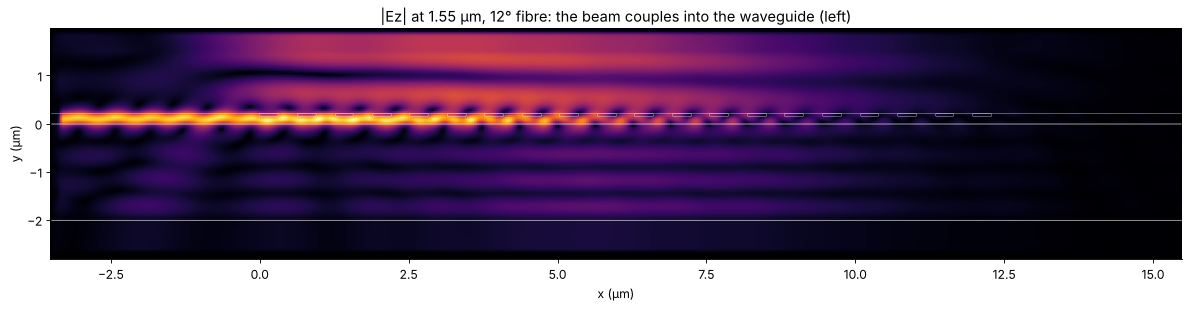

In [10]:
fig, ax = plt.subplots(figsize=(15, 4.0))
F = dft_g.field("Ez")[0]
x, y = dft_g.coords("Ez")
ax.imshow(np.abs(F).T, origin="lower", extent=fplot._extent((x, y)), cmap="inferno", aspect="auto")
fplot._structure_outline(ax, sim_g, color="w", lw=0.5)
ax.set(xlabel="x (µm)", ylabel="y (µm)", title="|Ez| at 1.55 µm, 12° fibre: the beam couples into the waveguide (left)")
plt.tight_layout()

## 4. A metalens

A **metasurface** replaces the curved surface of a lens by a flat layer
of sub-wavelength pillars. Each pillar delays the light by an amount set
by its width (a wider pillar holds more of the field in the high-index
material); arranging widths so that the delay follows the lens phase
$\varphi(x) = k_0(f - \sqrt{x^2 + f^2})$ (modulo 2π) makes a lens.

The design uses the **local-periodic approximation**: the transmission of
a pillar in the lens is taken from an infinite periodic array of equal
pillars. That library comes from periodic FDTD unit cells (Bloch
boundaries, notebook 62): `DiffractionOrders.coefficient(0)` is the
complex amplitude of the zeroth order, its ratio to a run without the
pillar the complex transmission $t(w)$. TiO₂ pillars (n = 2.4), 800 nm
tall, on glass, in a 300 nm period, at 633 nm, light from the glass side:

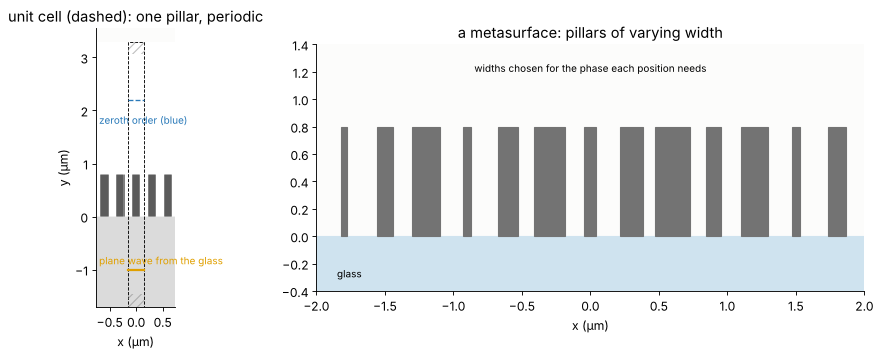

In [11]:
WL_M, N_T, N_G, P_M, H_M, h_m = 0.633, 2.4, 1.46, 0.3, 0.8, 0.02
TIO2, GLASS = fdtd.Medium.from_index(N_T), fdtd.Medium.from_index(N_G)
grid_u = fdtd.Grid((P_M, 5.0), h_m, center=(0, 0.8))


def unit_cell(w):
    st = [(fdtd.Slab(-10, 0, axis=1), GLASS)] + ([(fdtd.Rect((0, H_M/2), (w, H_M)), TIO2)] if w > 0 else [])
    src = fdtd.LineSource(-1.0, fdtd.GaussianPulse(WL_M, 0.2), axis=1)
    top = fdtd.DiffractionMonitor(2.2, [WL_M])
    return fdtd.Simulation(grid_u, st, [src], [top], mode="Ez", boundaries=("periodic", "pml")), top


fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
fplot.plot_structure(unit_cell(0.15)[0], ax=axs[0], periods=5)
axs[0].set(xlabel="x (µm)", ylabel="y (µm)", title="unit cell (dashed): one pillar, periodic")
axs[0].text(-0.7, 1.75, "zeroth order (blue)", color=fplot.MONITOR_COLOR, fontsize=9)
axs[0].text(-0.7, -0.9, "plane wave from the glass", color=fplot.SOURCE_COLOR, fontsize=9)
b = axs[1]
b.axhspan(-0.4, 0, color="#cfe3ef")
xs_demo = (np.arange(13) - 6)*P_M
w_demo = 0.04 + 0.22*np.mod(np.arange(13)*0.37, 1)
for xc, w in zip(xs_demo, w_demo):
    b.add_patch(plt.Rectangle((xc - w/2, 0), w, H_M, color="0.45"))
b.text(-1.85, -0.3, "glass", fontsize=9)
b.text(0, 1.2, "widths chosen for the phase each position needs", ha="center", fontsize=9)
b.set(xlim=(-2, 2), ylim=(-0.4, 1.4), aspect="equal", xlabel="x (µm)", title="a metasurface: pillars of varying width")
plt.tight_layout()

46 unit cells: 15 s
phase range 7.27 rad, |t| from 0.87 to 1.01


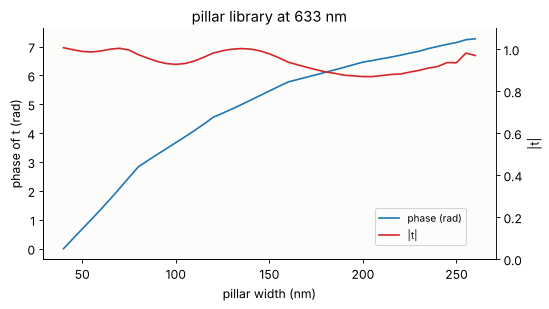

In [12]:
t0 = time.perf_counter()
sim0, ref = unit_cell(0)
sim0.run(time=60)
widths = np.arange(0.04, 0.265, 0.005)
lib = []
for w in widths:
    sim, top = unit_cell(w)
    sim.run(time=60)
    lib.append(top.orders().coefficient(0)[0]/ref.orders().coefficient(0)[0])
lib = np.array(lib)
print("%d unit cells: %.0f s" % (len(widths) + 1, time.perf_counter() - t0))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(widths*1e3, np.unwrap(np.angle(lib)) - np.angle(lib[0]), "C0", label="phase (rad)")
ax.set(xlabel="pillar width (nm)", ylabel="phase of t (rad)", title="pillar library at 633 nm")
ax2 = ax.twinx()
ax2.plot(widths*1e3, np.abs(lib), "C3", label="|t|")
ax2.set(ylim=(0, 1.1), ylabel="|t|")
ax2.spines["right"].set_visible(True)
fig.legend(loc="lower right", bbox_to_anchor=(0.85, 0.2), fontsize=9)
plt.tight_layout()
print("phase range %.2f rad, |t| from %.2f to %.2f" % (np.ptp(np.unwrap(np.angle(lib))),
                                                      np.abs(lib).min(), np.abs(lib).max()))

The library covers more than 2π with a transmission near one: every
phase is available. (|t| slightly above 1 is relative to the bare glass
surface, which reflects 3.5 %; some pillars act as an anti-reflection
layer.)

**The lens**: focal length 12 µm, aperture 24 µm (80 pillars, NA 0.71).
At each position the width whose $t$ is closest to $e^{i(\varphi(x) + c)}$
(with the constant $c$ that fits best overall). The full FDTD run of the
whole lens, a CW plane wave limited to the aperture from the glass side,
against the local-periodic model: each pillar's library $t$ over its
cell, propagated to the focus with the angular spectrum method.

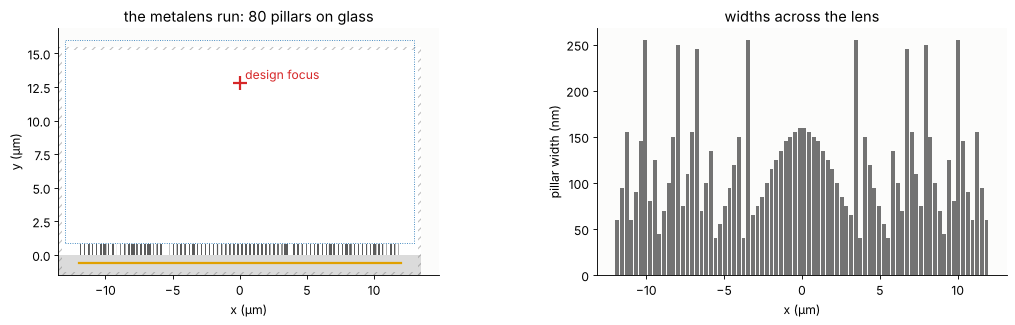

In [13]:
F_L, D_L = 12.0, 24.0
xs_l = (np.arange(int(D_L/P_M)) - (int(D_L/P_M) - 1)/2)*P_M
phi = 2*np.pi/WL_M*(F_L - np.sqrt(xs_l**2 + F_L**2))
best = None
for c in np.linspace(0, 2*np.pi, 72, endpoint=False):
    err = np.abs(lib[None, :] - np.exp(1j*(phi[:, None] + c)))
    j = err.argmin(1)
    e = err[np.arange(len(xs_l)), j].sum()
    if best is None or e < best[0]:
        best = (e, j)
jw = best[1]
lens = [(fdtd.Slab(-10, 0, axis=1), GLASS)] + [(fdtd.Rect((x, H_M/2), (w, H_M)), TIO2)
                                                for x, w in zip(xs_l, widths[jw])]
grid_l = fdtd.Grid((D_L + 3.0, 17.0), h_m, center=(0, 7.0))
dft_l = fdtd.DFTField([WL_M], components=["Ez"], start=40.0, region=((-D_L/2 - 1, D_L/2 + 1), (H_M + 0.1, F_L + 4)),
                      stride=2)
sim_l = fdtd.Simulation(grid_l, lens, [fdtd.LineSource(-0.6, fdtd.ContinuousWave(WL_M, ramp=8), axis=1,
                                                       extent=(-D_L/2, D_L/2))], [dft_l], mode="Ez")
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
fplot.plot_structure(sim_l, ax=axs[0])
axs[0].plot(0, F_L + H_M, "+", color="C3", ms=12, mew=2)
axs[0].text(0.4, F_L + H_M + 0.3, "design focus", color="C3")
axs[0].set(xlabel="x (µm)", ylabel="y (µm)", title="the metalens run: 80 pillars on glass")
axs[1].bar(xs_l, widths[jw]*1e3, width=0.25, color="0.45")
axs[1].set(xlabel="x (µm)", ylabel="pillar width (nm)", title="widths across the lens")
plt.tight_layout()

lens: 1350 x 850 cells, 14 s


focus at y = 12.58 µm (FDTD), 12.90 µm (model), design 12.80 µm
FWHM: FDTD 0.367 µm, model 0.383 µm, ideal 0.397 µm
total run time of the notebook: 532 s


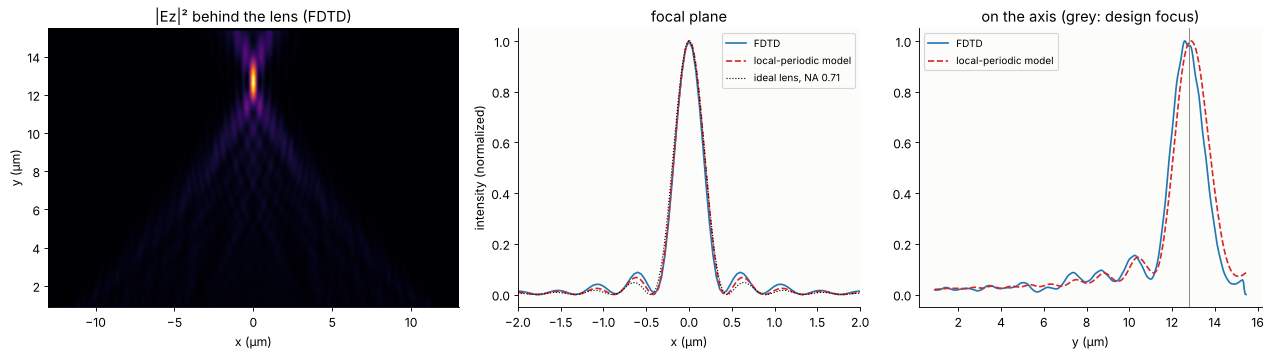

In [14]:
t0 = time.perf_counter()
sim_l.run(time=55)
print("lens: %d x %d cells, %.0f s" % (*grid_l.shape, time.perf_counter() - t0))
F = dft_l.field("Ez")[0]
x, y = dft_l.coords("Ez")
I = np.abs(F)**2
# local-periodic model, propagated with the angular spectrum method from the same plane
xx = np.arange(-40, 40, h_m/2)
tx = np.zeros(xx.shape, complex)
for xc, j in zip(xs_l, jw):
    tx[np.abs(xx - xc) <= P_M/2] = lib[j]
kx = 2*np.pi*np.fft.fftfreq(len(xx), xx[1] - xx[0])
kz = np.sqrt((2*np.pi/WL_M)**2 - kx**2 + 0j)
spec = np.fft.fft(tx)
I_lpa = np.array([np.abs(np.fft.ifft(spec*np.exp(1j*kz*(yy - y[0]))))**2 for yy in y]).T


def fwhm(xv, p):
    p = p/p.max()
    i = np.argmax(p)
    lo = np.interp(0.5, p[:i + 1], xv[:i + 1])
    hi = np.interp(0.5, p[i:][::-1], xv[i:][::-1])
    return hi - lo


ia, ja = np.argmin(np.abs(x)), np.argmin(np.abs(xx))
jf, jl = np.argmax(I[ia]), np.argmax(I_lpa[ja])
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.2, 1, 1]})
axs[0].imshow(I.T, origin="lower", extent=fplot._extent((x, y)), cmap="inferno", aspect="auto")
axs[0].set(xlabel="x (µm)", ylabel="y (µm)", title="|Ez|² behind the lens (FDTD)")
NA = np.sin(np.arctan(D_L/2/F_L))
xv = np.linspace(-2, 2, 801)
axs[1].plot(x, I[:, jf]/I[:, jf].max(), "C0", label="FDTD")
axs[1].plot(xx, I_lpa[:, jl]/I_lpa[:, jl].max(), "C3--", label="local-periodic model")
axs[1].plot(xv, np.sinc(2*NA*xv/WL_M)**2, "k:", lw=1, label="ideal lens, NA %.2f" % NA)
axs[1].set(xlim=(-2, 2), xlabel="x (µm)", ylabel="intensity (normalized)", title="focal plane")
axs[1].legend(fontsize=9)
axs[2].plot(y, I[ia]/I[ia].max(), "C0", label="FDTD")
axs[2].plot(y, I_lpa[ja]/I_lpa[ja].max(), "C3--", label="local-periodic model")
axs[2].axvline(F_L + H_M, color="0.5", lw=0.8)
axs[2].set(xlabel="y (µm)", title="on the axis (grey: design focus)")
axs[2].legend(fontsize=9)
plt.tight_layout()
print("focus at y = %.2f µm (FDTD), %.2f µm (model), design %.2f µm" % (y[jf], y[jl], F_L + H_M))
print("FWHM: FDTD %.3f µm, model %.3f µm, ideal %.3f µm"
      % (fwhm(x, I[:, jf]), fwhm(xx, I_lpa[:, jl]), fwhm(xv, np.sinc(2*NA*xv/WL_M)**2)))
print("total run time of the notebook: %.0f s" % (time.perf_counter() - t_start))

The lens focuses to the diffraction limit of its numerical aperture: the
focal spot is 0.37 µm wide (FWHM) in the FDTD, 0.38 µm in the
local-periodic model and 0.40 µm for an ideal lens with a uniform pupil;
the FDTD has slightly higher side lobes, the signature of a little more
weight at the edge of the pupil. The FDTD focus sits 0.2 µm closer to the
lens than designed (the model: 0.1 µm beyond): neighbouring pillars of very different widths
couple, which the local-periodic approximation ignores; the effect grows
with the numerical aperture, where the phase changes quickly from cell to
cell near the edge. A full FDTD run of the assembled lens is how such
designs are checked.

## Summary

- `fdtd.Lattice` places a shape on a lattice with removed or shifted
  sites: photonic crystals with line and point defects, gratings of
  pillars or trenches.
- A missing row of rods guides light inside the band gap; the supercell
  band (`bloch_modes` with `region`) crosses the gap, and a 90° bend
  passes almost all of the light: there is nowhere to radiate to.
- A missing rod is a cavity whose Q grows by a constant factor per ring,
  (5.9) from about 100 to 24 000 for five rings; the matrix pencil method
  reads it off short runs.
- A uniform grating coupler couples a bit under half of the light from a
  fibre into a silicon waveguide, at the wavelength set by the
  phase-matching condition; the peak moves by 8 nm per degree.
- `DiffractionOrders.coefficient` gives the complex transmission of
  periodic unit cells; a TiO₂ pillar library covers 2π, and a metalens
  assembled from it focuses to the diffraction limit, close to the
  local-periodic design.

Next (proposals/fdtd.md): 3D.